In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

## 1. Realizar el juego

Definir las escaleras, serpientes y condiciones del juego. Comienza en la casilla 1 y termina al llegar a la casilla 20.

In [11]:
# Escaleras y serpientes
escaleras = {3: 11, 15: 19}
serpientes = {13: 4, 17: 10}

INICIO = 1
META = 20

## 2. Simulación de una partida

Se crea una función que simula los lanzamientos de un dado. Si el jugador cae en una escalera o serpiente, se mueve a la casilla que le corresponda.

In [12]:
def simular_partida():

    posicion = INICIO
    tiradas = 0

    while posicion != META:

        dado = random.randint(1, 6)
        tiradas += 1

        nueva = posicion + dado

        # No se permite pasar de la casilla 20
        if nueva <= META:
            posicion = nueva

            # Revisar escaleras y serpientes
            if posicion in escaleras:
                posicion = escaleras[posicion]

            elif posicion in serpientes:
                posicion = serpientes[posicion]

    return tiradas

## 3. Prueba de funcionamiento

Realizar 10 partidas para observar cuántas tiradas se necesitan para llegar a la meta.

In [5]:
random.seed(2026)

resultados = [simular_partida() for _ in range(10)]

print("Tiradas de cada partida:")
print(resultados)

Tiradas de cada partida:
[6, 5, 8, 9, 12, 15, 24, 8, 4, 4]


## 4. Simulación Monte Carlo

Se realizan 100,000 partidas para obtener una mejor estimación del número esperado de tiradas.

In [6]:
N = 100000

partidas = [simular_partida() for _ in range(N)]

print("Total de partidas:", N)
print("Primeras 10 partidas:", partidas[:10])

Total de partidas: 100000
Primeras 10 partidas: [20, 22, 15, 10, 11, 9, 18, 14, 17, 18]


## 5. Número esperado de tiradas

Calcular el promedio de tiradas de todas las partidas (esto representa el número esperado de lanzamientos para terminar el juego).

In [7]:
esperado = np.mean(partidas)

print("Número esperado de tiradas:", esperado)

Número esperado de tiradas: 11.42395


## 6. Intervalo de confianza

Calcular el error estándar y el intervalo de confianza del 95% para conocer la precisión del promedio que se obtuvo.

In [8]:
ee = np.std(partidas, ddof=1) / np.sqrt(N)

limite_inferior = esperado - 1.96 * ee
limite_superior = esperado + 1.96 * ee

print("Error estándar:", ee)

print("Intervalo de confianza:",
      [limite_inferior, limite_superior])

Error estándar: 0.020138054011924634
Intervalo de confianza: [np.float64(11.384479414136628), np.float64(11.463420585863371)]


## 7. Gráfica de convergencia

En la siguiente gráfica, se observa cómo cambia el promedio de tiradas conforme aumenta el número de partidas simuladas.

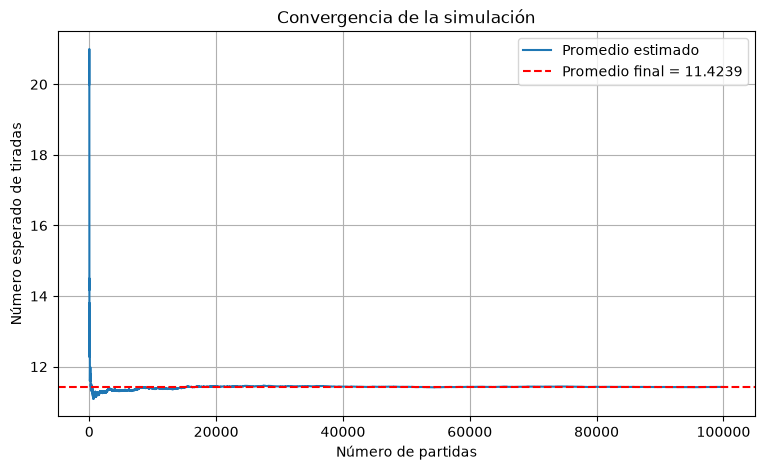

In [9]:
promedios = np.cumsum(partidas) / np.arange(1, N + 1)

plt.figure(figsize=(9, 5))

plt.plot(promedios, label="Promedio estimado")

plt.axhline(esperado, color="red", linestyle="--",
            label=f"Promedio final = {esperado:.4f}")

plt.xlabel("Número de partidas")
plt.ylabel("Número esperado de tiradas")
plt.title("Convergencia de la simulación")
plt.legend()
plt.grid()

plt.show()

In [10]:
print("CONCLUSIÓN")

print(f"Se realizaron {N:,} partidas mediante simulación Monte Carlo.")

print(f"El número esperado de tiradas para llegar a la "
      f"casilla 20 es aproximadamente {esperado:.4f}.")

print("Por lo tanto, se necesitan aproximadamente "
      f"{esperado:.2f} tiradas para terminar el juego.")

CONCLUSIÓN
Se realizaron 100,000 partidas mediante simulación Monte Carlo.
El número esperado de tiradas para llegar a la casilla 20 es aproximadamente 11.4239.
Por lo tanto, se necesitan aproximadamente 11.42 tiradas para terminar el juego.
